# 📘 통계 9–10장 실습: 가설검정의 주의점 · 인과와 상관

> 공부용 · 발표용 · 복습용 노트입니다.
> 각 문제는 **📖 상황 → 🧩 개념 → 💻 코드(주석) → 📝 해설 → 🧠 데이터 읽는 법(질문 + 이유)** 순서입니다.

## 📚 목차
- [⚙️ 환경 준비](#env)
- [📖 핵심 용어 사전](#dict)
- **1부 · 가설검정의 주의점**
  - [문제 1. 펭귄 두 종의 몸무게는 정말 다를까? (p-값 vs 효과크기)](#p1)
  - [문제 2. 그럼 몇 마리를 재야 할까? (검정력 분석)](#p2)
  - [문제 3. 유의한 결과는 '만들어질' 수 있다 (p-해킹)](#p3)
- **2부 · 인과와 상관**
  - [문제 4. 교란요인을 지우는 두 가지 방법 (통제 vs 무작위화)](#p4)
  - [문제 5. 실험할 수 없을 때 (PSM · DiD)](#p5)
- [🧠 마지막: 한눈에 보는 정리](#summary)

## 🎯 오늘의 큰 줄기 두 문장
1. **p-값은 "차이가 있는가", 효과크기는 "얼마나 큰가"에 답한다.** 그리고 p-값의 보장은 *절차를 지켰을 때만* 유효하다.
2. **상관을 인과로 읽으려면 교란요인을 지워야 한다.** 가장 강력한 방법은 무작위화(RCT), 안 될 때는 가정을 명시한 차선책(PSM·DiD)이다.

---
<a id="env"></a>
## ⚙️ 환경 준비
노트북을 열면 이 셀부터 실행하세요. 이후 셀은 **위에서부터 순서대로** 실행해야 합니다 (문제 2는 문제 1의 결과를, 문제 5는 문제 4의 데이터를 이어서 씁니다).

In [25]:
# ⚙️ 환경 준비 — 라이브러리 + 한글 폰트
# (코랩이라면 먼저 아래 주석을 풀어 설치 후 [런타임]-[세션 다시 시작])
# !pip install statsmodels scikit-learn
# !sudo apt-get install -y fonts-nanum && sudo fc-cache -fv && rm ~/.cache/matplotlib -rf

import platform
import warnings
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.power import TTestIndPower   # 검정력·표본크기 계산 도구
from sklearn.neighbors import NearestNeighbors      # 경향점수가 가장 가까운 짝 찾기

warnings.filterwarnings("ignore")

# 스타일을 먼저 적용한 뒤 한글 폰트를 지정해야 글꼴이 덮어써지지 않습니다.
sns.set_style("whitegrid")
system = platform.system()
if system == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"      # 맥
elif system == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"    # 윈도우
else:
    plt.rcParams["font.family"] = "NanumGothic"      # 코랩·리눅스
plt.rcParams["axes.unicode_minus"] = False           # 마이너스 기호 깨짐 방지

print("준비 완료!")

준비 완료!


---
<a id="dict"></a>
## 📖 핵심 용어 사전

| 용어 | 한 줄 뜻 | 이 노트에서 |
|---|---|---|
| **p-값** | H₀가 참이라고 가정할 때, 관찰한 만큼 극단적인 결과가 나올 확률. *H₀가 참일 확률이 아님* | 문제 1, 3 |
| **효과크기 (Cohen's d)** | 두 평균 차이를 '표준편차 몇 개만큼'으로 잰 값. 표본크기와 무관 | 문제 1, 2 |
| **제1종 오류 (α)** | 효과가 없는데 있다고 결론 (거짓 경보) | 문제 2, 3 |
| **제2종 오류 (β)** | 효과가 있는데 없다고 결론 (놓친 신호) | 문제 2 |
| **검정력 (1 − β)** | 진짜 효과가 있을 때 그것을 잡아낼 확률. 보통 80% 목표 | 문제 2 |
| **검정력 분석** | α, 검정력, 효과크기, n 중 셋을 정해 나머지 하나(보통 n)를 구하는 계산 | 문제 2 |
| **p-해킹** | 분석 방식을 바꿔가며 p-값을 0.05 아래로 밀어 넣는 행위 | 문제 3 |
| **다중비교 · 본페로니 보정** | 검정을 여러 번 하면 오류가 쌓이므로 기준을 α/검정횟수로 낮추는 방법 | 문제 3 |
| **교란변수 (중첩요인)** | 원인과 결과 양쪽에 영향을 주어 가짜 관계를 만드는 제3의 변수 | 문제 4 |
| **허위상관 · 심슨의 역설** | 교란 때문에 생긴 가짜 관계. 집단을 나누면 방향이 뒤집히기도 함 | 문제 4 |
| **RCT (무작위 통제 실험)** | 동전 던지기로 처치를 배정 → 모르는 교란까지 양쪽에 고르게 섞임 | 문제 4 |
| **경향점수 짝짓기 (PSM)** | 처치받을 확률이 비슷한 사람끼리 짝지어 '통계적 쌍둥이'를 만드는 방법 | 문제 5 |
| **ATT** | 처치를 실제로 받은 사람들에게서의 평균 처치효과 | 문제 5 |
| **이중차분법 (DiD)** | (실험군 변화) − (통제군 변화)로 정책효과를 추정. 평행추세 가정 필요 | 문제 5 |
| **플라시보 검정** | 효과가 없어야 할 곳에 같은 분석을 해서 0이 나오는지 보는 자기 반증 | 문제 5 |

> 💡 9장은 "**검정 결과를 어디까지 믿을 수 있나**", 10장은 "**관계를 원인으로 말할 수 있나**"를 다룹니다. 둘 다 결국 *숫자 하나로 결론을 내리지 말라*는 이야기입니다.

---
# 1부 · 가설검정의 주의점

<a id="p1"></a>
## 문제 1. 펭귄 두 종의 몸무게는 정말 다를까?

### 📖 상황
7장에서 Adelie 수컷 회귀가 "표본이 작아서" 유의하지 않았습니다. 이번엔 반대로 묻습니다. **표본을 아주 크게 만들면 무슨 일이 벌어질까?** Adelie와 Chinstrap의 몸무게 차이는 약 32g, 한 마리 몸무게의 1%도 안 됩니다.

### 🧩 개념
- **이표본 t-검정**: t = (두 평균의 차이) ÷ (차이의 표준오차). 표준오차 = σ/√n 꼴이라 **n이 커지면 분모가 작아져 t가 커지고, p는 작아집니다.**
- **Cohen's d** = (두 평균의 차이) ÷ (통합 표준편차). 분모가 *표준오차*가 아니라 *표준편차*이므로 **n과 무관**합니다.
- **통합 표준편차** s = √[((n₁−1)s₁² + (n₂−1)s₂²) / (n₁+n₂−2)] — 두 집단의 흩어짐을 표본 수만큼 가중평균한 값입니다.
- **관례 기준**: |d| 0.2 작음 / 0.5 중간 / 0.8 큼 (분야마다 다를 수 있는 '대략의 눈금').

In [26]:
# 문제 1 · 데이터 준비 — 펭귄 Adelie vs Chinstrap 몸무게
penguins = sns.load_dataset("penguins")
mass = penguins.dropna(subset=["body_mass_g", "species"])        # 몸무게·종이 있는 행만

adelie    = mass.loc[mass["species"] == "Adelie",    "body_mass_g"]
#gentoo    = mass.loc[mass["species"] == "gentoo",    "body_mass_g"]
chinstrap = mass.loc[mass["species"] == "Chinstrap", "body_mass_g"]

print("Adelie    n=%3d   평균 %.1f g   표준편차 %.1f g" % (len(adelie),    adelie.mean(),    adelie.std(ddof=1)))
#print("Gentoo    n=%3d   평균 %.1f g   표준편차 %.1f g" % (len(gentoo),    gentoo.mean(),    gentoo.std(ddof=1)))
print("Chinstrap n=%3d   평균 %.1f g   표준편차 %.1f g" % (len(chinstrap), chinstrap.mean(), chinstrap.std(ddof=1)))

diff_g = adelie.mean() - chinstrap.mean()                        # 두 종의 평균 차이
print("\n두 종의 평균 차이: %.1f g  (Adelie 몸무게의 약 %.1f%%)" % (diff_g, abs(diff_g) / adelie.mean() * 100))

Adelie    n=151   평균 3700.7 g   표준편차 458.6 g
Chinstrap n= 68   평균 3733.1 g   표준편차 384.3 g

두 종의 평균 차이: -32.4 g  (Adelie 몸무게의 약 0.9%)


### 💻 Q1 · 두 종의 몸무게를 t-검정으로 비교

In [27]:
# 문제 1 · Q1 — 이표본 t-검정
# H0: 두 종의 평균 몸무게는 같다 / H1: 다르다 (양측검정)
alpha = 0.05
t_stat, p_val = stats.ttest_ind(adelie, chinstrap)      # 통계량 t와 p-값을 함께 돌려줌

print(f"t = {t_stat:.3f},  p = {p_val:.3f}")
if p_val < alpha:
    print(f"p({p_val:.3f}) < {alpha} → H0 기각: 두 종의 평균 몸무게는 다르다")
else:
    print(f"p({p_val:.3f}) ≥ {alpha} → H0 기각 못함: 차이가 있다는 증거가 부족하다")

t = -0.508,  p = 0.612
p(0.612) ≥ 0.05 → H0 기각 못함: 차이가 있다는 증거가 부족하다


### 💻 Q2 · 효과크기(Cohen's d) 직접 계산

In [28]:
# 문제 1 · Q2 — 효과크기 Cohen's d 함수 만들기
def cohen_d(x, y):
    """두 집단의 평균 차이를 '통합 표준편차' 단위로 잰 효과크기"""
    nx, ny = len(x), len(y)
    sx, sy = np.std(x, ddof=1), np.std(y, ddof=1)                     # 표본표준편차 (n-1로 나눔)
    s_pooled = np.sqrt(((nx - 1) * sx**2 + (ny - 1) * sy**2) / (nx + ny - 2))   # 통합 표준편차
    return (np.mean(x) - np.mean(y)) / s_pooled                       # 분자: 평균 차이

d = cohen_d(adelie, chinstrap)
size = "작음 미만(거의 없음)" if abs(d) < 0.2 else "작음" if abs(d) < 0.5 else "중간" if abs(d) < 0.8 else "큼"
print(f"Cohen's d = {d:.3f}  → 관례 기준(0.2/0.5/0.8)으로 '{size}'")

Cohen's d = -0.074  → 관례 기준(0.2/0.5/0.8)으로 '작음 미만(거의 없음)'


### 💻 Q3 · 표본을 늘려 가며 p-값과 효과크기 추적 (400번 × 5개 n)

In [29]:
# 문제 1 · Q3 — 표본을 늘려 가며 p-값과 d를 추적
# 모집단 참값: '실제로 32g 차이 나는 두 집단'을 만든다
MU_A, MU_C = adelie.mean(), chinstrap.mean()
SIGMA = np.sqrt(((len(adelie) - 1) * adelie.std(ddof=1)**2 + (len(chinstrap) - 1) * chinstrap.std(ddof=1)**2)
                / (len(adelie) + len(chinstrap) - 2))

rng = np.random.default_rng(7)          # 재현성: 같은 시드면 같은 결과
REPS = 400                              # n마다 400번 반복
rows = []
for n in [30, 150, 1000, 5000, 20000]:
    pvals, ds = [], []
    for _ in range(REPS):
        a = rng.normal(MU_A, SIGMA, n)  # Adelie 모집단에서 n마리
        c = rng.normal(MU_C, SIGMA, n)  # Chinstrap 모집단에서 n마리
        pvals.append(stats.ttest_ind(a, c).pvalue)
        ds.append(cohen_d(a, c))
    pvals = np.array(pvals)
    rows.append({"n(집단당)": n,
                 "p-값 중위수": np.median(pvals),
                 "p<0.05 비율(%)": (pvals < 0.05).mean() * 100,
                 "Cohen's d 평균": np.mean(ds)})

sim = pd.DataFrame(rows)
sim.round({"p-값 중위수": 4, "p<0.05 비율(%)": 1, "Cohen's d 평균": 3})   # 열마다 소수점 자리 지정

,n(집단당),p-값 중위수,p<0.05 비율(%),Cohen's d 평균
0,30,0.4668,5.8,-0.081
1,150,0.4421,9.5,-0.069
2,1000,0.0841,39.2,-0.075
3,5000,0.0002,95.5,-0.075
4,20000,0.0000,100.0,-0.074


### 💻 Q4 · 그래프로 비교

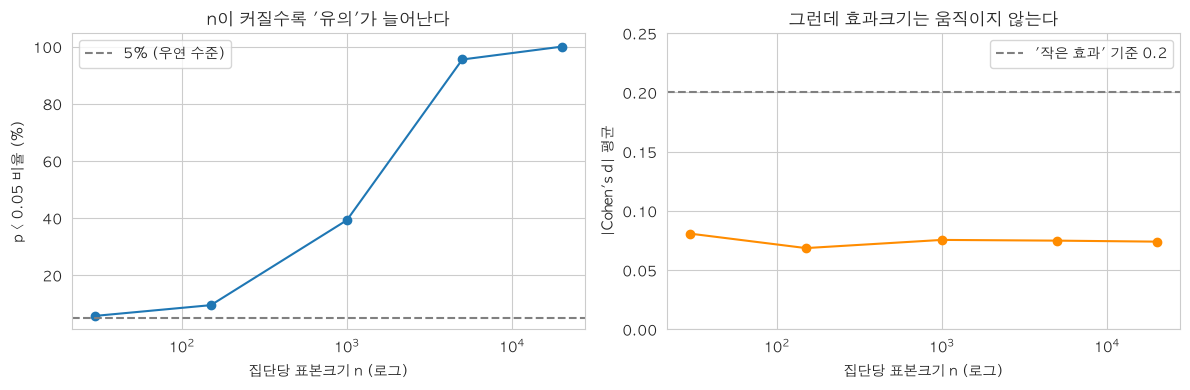

In [30]:
# 문제 1 · Q4 — 그래프: n에 따른 유의 비율 vs 효과크기
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(sim["n(집단당)"], sim["p<0.05 비율(%)"], marker="o")
ax[0].set_xscale("log")                                   # n이 30~20000이라 로그 눈금
ax[0].axhline(5, color="gray", linestyle="--", label="5% (우연 수준)")
ax[0].set_title("n이 커질수록 '유의'가 늘어난다")
ax[0].set_xlabel("집단당 표본크기 n (로그)"); ax[0].set_ylabel("p < 0.05 비율 (%)")
ax[0].legend()

# d는 Adelie − Chinstrap이라 음수 → 크기를 보기 위해 절대값으로 그림
ax[1].plot(sim["n(집단당)"], sim["Cohen's d 평균"].abs(), marker="o", color="darkorange")
ax[1].set_xscale("log")
ax[1].set_ylim(0, 0.25)
ax[1].axhline(0.2, color="gray", linestyle="--", label="'작은 효과' 기준 0.2")
ax[1].set_title("그런데 효과크기는 움직이지 않는다")
ax[1].set_xlabel("집단당 표본크기 n (로그)"); ax[1].set_ylabel("|Cohen's d| 평균")
ax[1].legend()

plt.tight_layout()
plt.show()

### 📝 해석

**결론: 32g 차이는 n이 작을 땐 유의하지 않지만(p = 0.61), n을 키우면 거의 확실하게 '유의'해진다. 그런데 효과크기는 n과 상관없이 약 0.07로 그대로다.**

| n(집단당) | p-값 중위수 | p<0.05 비율 | Cohen's d 평균 |
|---|---|---|---|
| 30 | 0.467 | 5.8% | −0.081 |
| 150 | 0.442 | 9.5% | −0.069 |
| 1,000 | 0.084 | 39.2% | −0.075 |
| 5,000 | 0.0002 | 95.5% | −0.075 |
| 20,000 | ≈0 | 100% | −0.074 |

- **p-값 열은 n에 따라 움직이고, d 열은 꼼짝하지 않습니다.**
- d가 음수인 것은 계산 방향이 Adelie − Chinstrap이기 때문입니다(Adelie가 32g 가벼움). 크기는 절대값 0.074로 봅니다.
- n = 30일 때 유의 비율 5.8%는 우연 수준(5%)과 거의 같습니다. 효과가 너무 작아서 사실상 '차이 없음'과 구별이 안 되는 것입니다.

### 🧠 데이터를 어떻게 읽을까요?

**Q1. Q1에서는 유의하지 않았는데 Q3의 n = 5,000에서는 95% 이상 유의했습니다. 같은 32g인데 결론이 갈린 이유는?**
→ **차이의 크기가 아니라 표본크기가 달라졌기 때문입니다.**
- 이유: t-통계량의 분모(표준오차)는 √n에 반비례해 줄어듭니다. 차이(분자)는 그대로 32g인데 분모가 계속 작아지니 t가 커지고 p가 작아집니다. 실제 데이터는 Adelie 151마리, Chinstrap 68마리라 분모가 커서 32g이 흔들림에 묻혔습니다.

**Q2. n이 커질 때 p-값과 d는 각각 어떻게 변했고, 이 대비가 뜻하는 바는?**
→ **p-값은 0을 향해 줄고, d는 약 0.07로 그대로였습니다. 즉 "p-값은 표본크기를 반영하고, 효과크기는 차이 자체를 반영한다."**
- 이유: p-값의 계산에는 n이 들어가지만, d는 표준편차로 나누므로 n이 들어가지 않습니다. 그래서 p-값만 보면 '데이터를 많이 모은 사람'이 늘 이기는 구조가 됩니다.

**Q3. "통계적으로 유의하다"와 "실질적으로 의미 있다"는 같은 말인가요?**
→ **다릅니다.** n = 20,000이면 32g 차이도 100% 유의하지만, 32g은 몸무게의 0.9%이고 d = 0.07로 '작은 효과' 기준(0.2)의 3분의 1에 불과합니다.
- 이유: 유의성은 "우연이 아닐 가능성"이고, 실질적 의미는 "그 차이가 현실에서 중요한가"입니다. 저울 눈금 하나 차이로 "종에 따라 몸무게가 다르다"고 쓰면, 통계적으로는 맞아도 생물학적으로는 과장입니다.

**Q4. A/B 테스트에서 클릭률 0.1%p 상승, p = 0.001. 이것만으로 버튼을 바꿔야 할까요?**
→ **이것만으로는 말할 수 없습니다.** p = 0.001은 "우연은 아닐 것"만 말해 줍니다.
- 이유: 0.1%p가 매출로 얼마인지, 버튼 변경 비용은 얼마인지, 신뢰구간이 0에 얼마나 가까운지를 함께 봐야 합니다. 대형 서비스는 표본이 수백만이라 아주 작은 차이도 p가 작게 나옵니다. 변경 비용이 거의 없으면 바꿔도 되지만, 큰 개편이 필요하다면 0.1%p는 부족할 수 있습니다.

**Q5. 보고서에 p-값만 적는 것이 왜 부족한가요? 무엇을 함께 적어야 하나요?**
→ **효과크기(차이와 d), 신뢰구간, 표본크기를 함께 적어야 합니다.**
- 이유: p-값만 있으면 "차이가 큰데 표본이 작은 연구"와 "차이가 아주 작은데 표본이 큰 연구"를 구별할 수 없습니다. 미국통계협회(ASA)가 2016년 성명에서 "p-값 하나로 과학적 결론을 대신하지 말라"고 한 이유가 이것입니다.
- 예시 문장: *"Adelie는 Chinstrap보다 평균 32g 가벼웠으나(d = −0.07, 95% CI는 0을 포함), 차이는 유의하지 않았다(p = 0.61, n = 151/68)."*

🔗 **연결:** 이 결과를 뒤집어 읽으면 "n이 모자라면 진짜 차이도 놓친다"가 됩니다. 그게 다음 문제의 검정력입니다.


In [31]:
# 두 평균 차이의 95% 신뢰구간 (등분산 가정, t-검정과 같은 방식)
na, nc = len(adelie), len(chinstrap)
diff = adelie.mean() - chinstrap.mean()                                   # ① 평균 차이
sp = np.sqrt(((na-1)*adelie.var(ddof=1) + (nc-1)*chinstrap.var(ddof=1))
             / (na + nc - 2))                                             # ② 통합 표준편차
se = sp * np.sqrt(1/na + 1/nc)                                            # ③ 차이의 표준오차
dof = na + nc - 2                                                         # ④ 자유도
t_crit = stats.t.ppf(0.975, dof)                                          # ⑤ 95% → 0.975
lo, hi = diff - t_crit * se, diff + t_crit * se                           # ⑥ 구간

print(f"평균 차이 {diff:.1f} g, 95% CI [{lo:.1f}, {hi:.1f}] g")
print("0을 포함 → 유의하지 않음" if lo < 0 < hi else "0을 포함하지 않음 → 유의함")

평균 차이 -32.4 g, 95% CI [-158.2, 93.4] g
0을 포함 → 유의하지 않음


## 🔑 [부록] 신뢰구간을 꼭 봐야 되는 이유

> **p-값은 "차이가 0인가 아닌가"만 말하지만, 신뢰구간은 "차이가 어디에서 어디까지일 수 있는가"를 말한다.**
> 그래서 신뢰구간 하나로 **유의성(검정) · 크기 · 불확실성**을 한 번에 볼 수 있다.

---

## 1. 신뢰구간 구하는 법 (펭귄 두 종 몸무게 차이)

**신뢰구간 = (평균 차이) ± t임계값 × (차이의 표준오차)**

### 단계별 계산

| 단계 | 식 | 펭귄 값 |
|---|---|---|
| ① 평균 차이 | x̄_A − x̄_C | 3700.7 − 3733.1 = **−32.4 g** |
| ② 통합 표준편차 | s = √[((n₁−1)s₁² + (n₂−1)s₂²) / (n₁+n₂−2)] | **437.0 g** |
| ③ 차이의 표준오차 | SE = s × √(1/n₁ + 1/n₂) | 437.0 × √(1/151 + 1/68) = **63.8 g** |
| ④ 자유도 | n₁ + n₂ − 2 | **217** |
| ⑤ t임계값 (95%) | 양쪽 2.5%씩 → t(0.975, 217) | **1.97** |
| ⑥ 신뢰구간 | −32.4 ± 1.97 × 63.8 | **[−158.2 g, +93.4 g]** |

> 💡 ③에서 표준편차(437g)가 아니라 **표준오차(63.8g)**를 쓰는 것이 핵심이다.
> - **표준편차**: 펭귄 한 마리 한 마리의 흩어짐
> - **표준오차**: 평균 차이라는 *추정치 자체*의 흔들림

---

## 2. 신뢰구간으로 검정하는 법

**규칙: 95% 신뢰구간이 0을 포함하면 → α = 0.05 양측검정에서 H₀(차이 = 0)를 기각하지 못한다. 포함하지 않으면 → 기각한다.**

- 펭귄: [−158.2, +93.4]는 0을 포함 → **기각 못함**
- t-검정의 p = 0.61과 **같은 결론**

### 왜 두 방법이 같은 결론을 내나

두 방법은 **같은 재료(평균 차이, 표준오차, t임계값)를 다른 방향에서** 본 것이다.

| | t-검정 | 신뢰구간 |
|---|---|---|
| 질문 | 차이가 0이라고 치면, 관찰값은 0에서 얼마나 멀리 있나? | 관찰값을 중심으로, 참값이 있을 법한 범위는? |
| 계산 | t = −32.4 ÷ 63.8 = **−0.51** | −32.4 ± **1.97** × 63.8 |
| 판정 | \|t\| = 0.51 < 1.97 → 기각 못함 | 0이 구간 안 → 기각 못함 |

- **"|t| < 1.97"**과 **"0이 구간 안에 있다"**는 수학적으로 같은 말이다.
- 평균 차이가 0에서 표준오차 1.97개 이내에 있으면, 거꾸로 0도 평균 차이에서 표준오차 1.97개 이내에 있기 때문이다.

> ⚠️ 이 대응은 **95% 구간 ↔ α = 0.05 양측검정**처럼 짝이 맞을 때만 성립한다. 99% 구간이면 α = 0.01과 짝이다.

---

## 3. 왜 p-값 말고 신뢰구간을 같이 봐야 하나

검정 결론이 같다면 신뢰구간이 왜 필요할까? **신뢰구간은 p-값이 버리는 정보 두 가지를 더 준다.**

### ① 크기 — "유의하다"가 "중요하다"인지 알려 준다

문제 1에서 n을 늘리면, 같은 32g 차이의 신뢰구간은 이렇게 변한다 (참값 −32.4g 가정).

| 집단당 n | 95% 신뢰구간 (g) | 0 포함? | 판정 |
|---|---|---|---|
| 151 / 68 (실제) | [−158, +93] | 포함 | 유의하지 않음 |
| 5,000 | [−50, −15] | 미포함 | 유의함 |
| 20,000 | [−41, −24] | 미포함 | 유의함 |

- n = 20,000에서 p-값은 거의 0 → p-값만 보면 "매우 강력한 결과"처럼 들린다.
- 신뢰구간을 보면 **"차이는 기껏해야 24~41g, 몸무게의 1% 안팎"**이 바로 보인다.
- → **유의하지만 생물학적으로는 작은 차이**라는 판단은 신뢰구간에서 나온다.

### ② 불확실성 — "유의하지 않음"이 "차이 없음"인지 알려 준다

실제 데이터의 구간 **[−158, +93]**을 다시 보면,

- 0을 포함하니 "유의하지 않음"이다.
- 그런데 구간 안에는 **Adelie가 158g 가벼울 가능성**도, **93g 무거울 가능성**도 들어 있다.
- 즉 이 결과는 "차이가 없다"가 아니라 **"차이의 방향조차 모를 만큼 정보가 부족하다"**는 뜻이다.
- 구간의 폭(약 250g)이 문제 2의 **검정력 부족**을 그대로 보여 준다.

### 같은 p-값, 다른 신뢰구간

| | 연구 A | 연구 B |
|---|---|---|
| p-값 | 0.03 | 0.03 |
| 95% CI | [0.5g, 9.5g] | [50g, 950g] |
| 해석 | 차이는 확실하지만 **아주 작다** | 차이가 클 수 있지만 **범위가 넓어 불확실하다** |

> p-값만 적으면 두 연구가 똑같아 보인다. 신뢰구간을 적어야 독자가 이 차이를 알 수 있다.

---

## 4. 신뢰구간을 읽는 세 가지 질문

1. **0을 포함하는가?** → 유의성 (검정 결론)
2. **구간 전체가 '의미 있는 크기'보다 큰가, 작은가?** → 실질적 중요성
   - 예: "50g 이상이어야 의미 있다"면, [−41, −24]는 *유의하지만 의미 없는* 차이
3. **구간이 넓은가, 좁은가?** → 불확실성 (넓으면 정보 부족 → 더 모아야 함)

---

## 5. 보고 문장 다시 쓰기

**❌ p-값만:**
> 차이는 유의하지 않았다(p = 0.61).

**✅ 신뢰구간까지:**
> Adelie는 Chinstrap보다 평균 32g 가벼웠으나, 95% 신뢰구간은 −158g에서 +93g으로 0을 포함해 유의한 차이는 확인되지 않았다(p = 0.61, n = 151/68). 구간이 넓어 차이의 방향과 크기를 판단하기에는 정보가 부족하다.

두 번째 문장은 독자에게 **결론 · 크기 · 불확실성 · 다음에 할 일(더 모으기)**까지 전달한다.

---

## 🔑 한 줄 정리

> **신뢰구간은 같은 계산으로 검정 결과(0을 포함하는가)를 주면서, p-값이 버리는 차이의 크기와 추정의 불확실성까지 보여 준다. 그래서 p-값 옆에는 신뢰구간을 함께 적어야 한다.**

---
<a id="p2"></a>
## 문제 2. 그럼 몇 마리를 재야 할까?

### 📖 상황
문제 1은 "n을 늘리면 유의해진다"를 보여줬습니다. 뒤집으면 무서운 말입니다 — **n이 모자라면 진짜 있는 차이도 놓친다.** 그래서 실험 *전에* 필요한 표본수를 계산합니다.

### 🧩 개념
- **제2종 오류(β)**: 진짜 차이가 있는데 놓치는 실수. **검정력 = 1 − β**, 관례적 목표 80%.
- **검정력을 정하는 네 값**: α, 검정력, 효과크기 d, 집단당 n. **셋을 정하면 나머지 하나가 정해집니다.** `solve_power`는 이 방정식을 푸는 함수입니다.
- **필요 n은 대략 1/d²에 비례**합니다. 효과가 절반으로 작아지면 표본은 네 배가 필요합니다 (표준오차가 √n에 반비례하기 때문).
- **효과크기를 얼마로 정할지**는 통계가 아니라 도메인(현장) 지식이 정합니다.

In [32]:
# 문제 2 · 데이터 준비 — 검정력 분석 도구
# 문제 1의 Q2·Q3를 먼저 완료해야 이 문제를 풀 수 있습니다.

analysis = TTestIndPower()   # 검정력 분석 도구

print("검정력 분석에 쓰이는 네 개의 값")
print("  ① 유의수준 alpha  — 제1종 오류를 허용하는 한계 (보통 0.05)")
print("  ② 검정력 power    — 1 - beta, 진짜 차이를 잡아낼 확률 (보통 0.80)")
print("  ③ 효과크기 d      — 검출하고자 하는 차이의 크기")
print("  ④ 표본크기 nobs1  — 집단당 표본 수")
print("\n→ 이 중 셋을 정하면 나머지 하나가 결정됩니다.")

검정력 분석에 쓰이는 네 개의 값
  ① 유의수준 alpha  — 제1종 오류를 허용하는 한계 (보통 0.05)
  ② 검정력 power    — 1 - beta, 진짜 차이를 잡아낼 확률 (보통 0.80)
  ③ 효과크기 d      — 검출하고자 하는 차이의 크기
  ④ 표본크기 nobs1  — 집단당 표본 수

→ 이 중 셋을 정하면 나머지 하나가 결정됩니다.


In [33]:
# 문제 2 · Q1 — 두 가지 오류 표 (정답 예시)
#                         | H0 기각 (효과가 있다고 결론)          | H0 기각 못함 (효과가 없다고 결론)
# 실제로 효과가 없을 때    | ❌ 제1종 오류(α): 거짓 경보            | ✅ 올바른 판단
#                         |   → 효과 없는 약을 승인, 돈·건강 손실   |
# 실제로 효과가 있을 때    | ✅ 올바른 판단 (확률 = 검정력 1−β)     | ❌ 제2종 오류(β): 놓친 신호
#                         |                                       |   → 좋은 약을 버림, 치료 기회 손실
#
# 제1종 오류를 범하면 잃는 것: 효과 없는 약에 쓰는 비용, 환자의 부작용 위험, 과학적 신뢰
# 제2종 오류를 범하면 잃는 것: 실제로 효과 있는 약을 놓쳐 환자가 치료받을 기회를 잃음
# 검정력(1−β) 한 문장 정의 : 진짜 효과가 있을 때, 그 효과를 '있다'고 잡아낼 확률

### 💻 Q2 · 문제 1의 시뮬레이션이 이론과 맞는지 확인

In [34]:
# 문제 2 · Q2 — 시뮬레이션(문제 1) vs 이론 검정력 비교
d_peng = abs(d)                                  # 펭귄 효과크기 절대값 (약 0.074)
compare = sim[["n(집단당)", "p<0.05 비율(%)"]].copy()
compare["이론 검정력(%)"] = [analysis.power(effect_size=d_peng, nobs1=n, alpha=0.05, ratio=1) * 100
                         for n in compare["n(집단당)"]]
compare.round(1)

,n(집단당),p<0.05 비율(%),이론 검정력(%)
0,30,5.8,5.9
1,150,9.5,9.8
2,1000,39.2,38.2
3,5000,95.5,96.0
4,20000,100.0,100.0


### 💻 Q3 · 검정력 80%에 필요한 표본수

In [35]:
# 문제 2 · Q3 — 검정력 80%에 필요한 집단당 표본수
rows = []
for label, es in [("펭귄 d≈%.3f" % d_peng, d_peng), ("작음 0.2", 0.2), ("중간 0.5", 0.5), ("큼 0.8", 0.8)]:
    n_need = analysis.solve_power(effect_size=es, alpha=0.05, power=0.8)   # n을 미지수로 풀기
    rows.append({"효과크기": label, "집단당 필요 n": int(np.ceil(n_need))})   # 사람 수는 올림
need = pd.DataFrame(rows)
print(need.to_string(index=False))

# (정리 질문 확인용) alpha를 0.01로 낮추면?
n_01 = np.ceil(analysis.solve_power(effect_size=0.5, alpha=0.01, power=0.8))
print(f"\n참고: d=0.5에서 alpha=0.01이면 집단당 {int(n_01)}명 필요 (alpha=0.05일 때보다 많음)")

      효과크기  집단당 필요 n
펭귄 d≈0.074      2852
    작음 0.2       394
    중간 0.5        64
     큼 0.8        26

참고: d=0.5에서 alpha=0.01이면 집단당 96명 필요 (alpha=0.05일 때보다 많음)


### 💻 Q4 · 검정력 곡선 (d = 0.5)

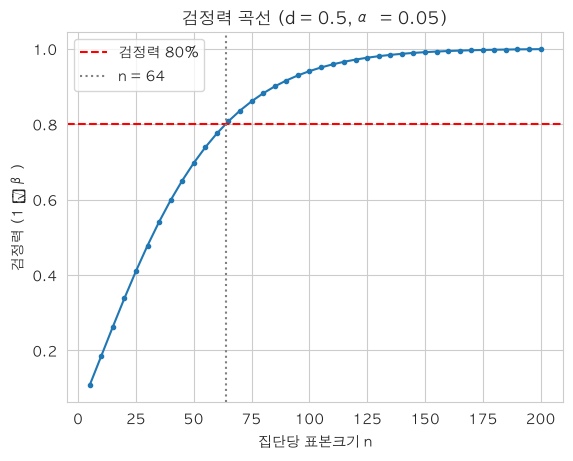

In [36]:
# 문제 2 · Q4 — 검정력 곡선 (d = 0.5)
n_list = np.arange(5, 201, 5)
powers = [analysis.power(effect_size=0.5, nobs1=n, alpha=0.05) for n in n_list]
n80 = int(np.ceil(analysis.solve_power(effect_size=0.5, alpha=0.05, power=0.8)))

plt.plot(n_list, powers, marker=".")
plt.axhline(0.8, color="red", linestyle="--", label="검정력 80%")
plt.axvline(n80, color="gray", linestyle=":", label=f"n = {n80}")
plt.title("검정력 곡선 (d = 0.5, α = 0.05)")
plt.xlabel("집단당 표본크기 n"); plt.ylabel("검정력 (1 − β)")
plt.legend(); plt.show()

### 📝 해석

**결론: 문제 1의 시뮬레이션 결과는 이론 검정력과 거의 정확히 일치한다. 그리고 펭귄의 32g(d ≈ 0.074)을 80% 검정력으로 잡으려면 집단당 약 2,852마리가 필요하다.**

| 효과크기 | 집단당 필요 n (α=0.05, 검정력 80%) |
|---|---|
| 펭귄 d ≈ 0.074 | 2,852 |
| 작음 0.2 | 394 |
| 중간 0.5 | 64 |
| 큼 0.8 | 26 |

- 시뮬레이션 'p<0.05 비율'(5.8 / 9.5 / 39.2 / 95.5 / 100%)과 이론 검정력(5.9 / 9.8 / 38.2 / 96.0 / 100%)이 거의 같습니다. **문제 1에서 센 '유의 비율'이 바로 검정력**이었던 것입니다.
- 검정력 곡선은 n = 64 근처에서 80% 선을 넘습니다. Q3의 계산과 같습니다.
- d가 0.5 → 0.074로 약 6.8배 작아지자 필요 n은 64 → 2,852로 약 45배(≈6.8²) 늘었습니다. 1/d² 관계가 그대로 보입니다.

### 🧠 데이터를 어떻게 읽을까요?

**Q1. 32g을 80% 검정력으로 잡으려면 몇 마리가 필요했나요? 팔머 기지 데이터(전체 344마리)로 이 연구는 가능했을까요?**
→ **집단당 2,852마리, 두 종 합쳐 약 5,700마리가 필요했습니다. 344마리로는 애초에 불가능한 연구였습니다.**
- 이유: 실제 데이터의 검정력은 10% 안팎입니다. 진짜 32g 차이가 있어도 10번 중 9번은 놓치는 설계였습니다.

**Q2. 검정력이 낮은 연구에서 "유의한 차이가 없었다"는 결과로 무엇을 알 수 있고, 무엇을 알 수 없나요?**
→ **"큰 차이는 아마 없다" 정도는 말할 수 있지만, "차이가 없다"는 말할 수 없습니다.**
- 이유: 검정력이 20%라면 진짜 차이가 있어도 5번 중 4번은 놓칩니다. 그런 연구의 '차이 없음'은 증거가 아니라 **정보 부족**입니다. 7장의 Adelie 수컷 회귀(n = 73, p = 0.061)도 같은 경우입니다.

**Q3. 실험 전에 표본수를 정해야 하는 이유는? 데이터를 본 뒤에 정하면 무엇이 잘못될까요?**
→ **데이터를 본 뒤 정하면 "결과를 보고 규칙을 바꾸는 것"이 되어 제1종 오류가 부풀어 오릅니다.**
- 이유: p가 0.05 근처에서 맴돌 때 "조금만 더 모으자"를 반복하면 우연히 0.05 아래로 내려가는 순간을 잡게 됩니다. 이것이 바로 다음 문제의 '표본 추가형 p-해킹'입니다.

**Q4. α를 0.05에서 0.01로 낮추면 필요한 n은 늘어날까요, 줄어들까요?**
→ **늘어납니다.** d = 0.5에서 집단당 64명 → 96명이 됩니다.
- 이유: 거짓 경보 기준을 엄격하게 하면, 같은 검정력을 유지하기 위해 더 강한 증거(더 작은 표준오차)가 필요합니다. α와 β는 서로 맞바꾸는 관계이고, 둘 다 낮추려면 n을 늘리는 수밖에 없습니다.

**Q5. "검출하고자 하는 효과크기를 얼마로 정할 것인가"는 통계 문제인가요, 도메인 문제인가요?**
→ **도메인 문제입니다.**
- 이유: 고혈압 약이 혈압을 몇 mmHg 낮춰야 임상적으로 의미 있는지는 의사가 정합니다. 통계는 그 숫자를 받아 필요한 n을 계산해 줄 뿐입니다. A/B 테스트라면 "전환율이 몇 %p 올라야 개발 비용을 회수하는가"를 사업 쪽에서 정합니다.


---
<a id="p3"></a>
## 문제 3. 유의한 결과는 '만들어질' 수 있다

### 📖 상황
심리학 연구 100건을 재실험했더니 원래 유의했던 97건 중 36건만 다시 유의했습니다. 이것이 **재현성 위기**입니다. 원인 중 하나가 **p-해킹**입니다. 이번엔 *아무 차이도 없는* 두 집단을 놓고, 분석 방식만 바꿔 '유의한 결과'를 얼마나 만들 수 있는지 직접 세어 봅니다.

### 🧩 개념
- 진짜 차이가 0이므로 **유의하다는 결론은 전부 제1종 오류**입니다. 절차를 지키면 5%여야 합니다.
- **해킹 ① 표본 추가형(optional stopping)**: 결과를 보며 "유의할 때까지" 표본을 더함 → 같은 질문을 여러 번 던지는 것.
- **해킹 ② 다중비교형(cherry picking)**: 지표를 여러 개 재고 유의한 것만 보고 → 여러 질문 중 하나만 골라 내는 것.
- **k번 독립 검정에서 하나라도 우연히 걸릴 확률 = 1 − (1 − α)ᵏ.** 20번이면 1 − 0.95²⁰ ≈ 64%.
- **본페로니 보정**: 각 검정의 기준을 α / k로 낮춰 전체 오류율을 α 이하로 묶는 방법입니다.

In [37]:
# 문제 3 · 데이터 준비 — 진짜 차이가 '0'인 세계
N_SIM = 1000     # 시뮬레이션 반복 횟수
SEED  = 777      # 난수 시드 — Q1~Q4에서 각각 이 값으로 시작하면 몇 번 재실행해도 같은 결과가 나옵니다

print("이번 문제의 전제")
print("  두 집단 A, B는 모두 N(0, 1)에서 나옵니다 → 진짜 차이는 정확히 0")
print("  즉 귀무가설이 '참'인 상황이며, 유의하다는 결론은 모두 제1종 오류입니다.")
print("  절차를 지켰다면 오류율은 유의수준 5% 근처여야 합니다.")
print("\n각 조건마다 %d번씩 반복해 '유의하다고 결론 내린 비율'을 셉니다." % N_SIM)

이번 문제의 전제
  두 집단 A, B는 모두 N(0, 1)에서 나옵니다 → 진짜 차이는 정확히 0
  즉 귀무가설이 '참'인 상황이며, 유의하다는 결론은 모두 제1종 오류입니다.
  절차를 지켰다면 오류율은 유의수준 5% 근처여야 합니다.

각 조건마다 1000번씩 반복해 '유의하다고 결론 내린 비율'을 셉니다.


### 💻 Q1 · 정직한 분석의 제1종 오류율

In [38]:
# 문제 3 · Q1 — 정직한 분석: 20명씩, 딱 한 번 검정
rng = np.random.default_rng(SEED)
hits = 0
for _ in range(N_SIM):
    a = rng.normal(0, 1, 20)
    b = rng.normal(0, 1, 20)
    if stats.ttest_ind(a, b).pvalue < 0.05:     # 우연히 유의하게 나온 경우만 셈
        hits += 1
honest = hits / N_SIM * 100
print(f"정직한 분석의 제1종 오류율: {honest:.1f}%  (기대값 5%)")

정직한 분석의 제1종 오류율: 4.9%  (기대값 5%)


### 💻 Q2 · 해킹 ① 결과를 보고 표본을 더 모으면

In [39]:
# 문제 3 · Q2 — 해킹 ①: 결과를 보며 표본을 더 모으기
def p_hacker(rng, start=20, add=10, max_tries=5):
    """20명으로 시작 → 유의하면 멈춤, 아니면 10명씩 추가해 최대 5번 검정"""
    a = list(rng.normal(0, 1, start))
    b = list(rng.normal(0, 1, start))
    for _ in range(max_tries):
        if stats.ttest_ind(a, b).pvalue < 0.05:
            return True                          # "찾았다!" 하고 즉시 멈춤
        a.extend(rng.normal(0, 1, add))          # 표본 추가
        b.extend(rng.normal(0, 1, add))
    return False

rng = np.random.default_rng(SEED)
peek = np.mean([p_hacker(rng) for _ in range(N_SIM)]) * 100
print(f"표본 추가형 해킹의 오류율: {peek:.1f}%  (정직한 분석 {honest:.1f}%)")

표본 추가형 해킹의 오류율: 13.5%  (정직한 분석 4.9%)


### 💻 Q3 · 해킹 ② 지표 20개 중 유의한 하나만 보고하면

In [40]:
# 문제 3 · Q3 — 해킹 ②: 지표 20개 중 유의한 하나만 보고
def many_metrics(rng, k=20, n=20, cutoff=0.05):
    """차이 없는 지표 k개를 각각 검정 → 하나라도 cutoff 미만이면 '성공'"""
    return any(stats.ttest_ind(rng.normal(0, 1, n), rng.normal(0, 1, n)).pvalue < cutoff
               for _ in range(k))

rng = np.random.default_rng(SEED)
multi = np.mean([many_metrics(rng) for _ in range(N_SIM)]) * 100
theory = (1 - 0.95**20) * 100                    # 20번 중 한 번이라도 우연히 걸릴 확률
print(f"다중비교형 해킹의 오류율: {multi:.1f}%   이론값 1 − 0.95²⁰ = {theory:.1f}%")

다중비교형 해킹의 오류율: 64.8%   이론값 1 − 0.95²⁰ = 64.2%


### 💻 Q4 · 본페로니 보정 + 네 결과 비교

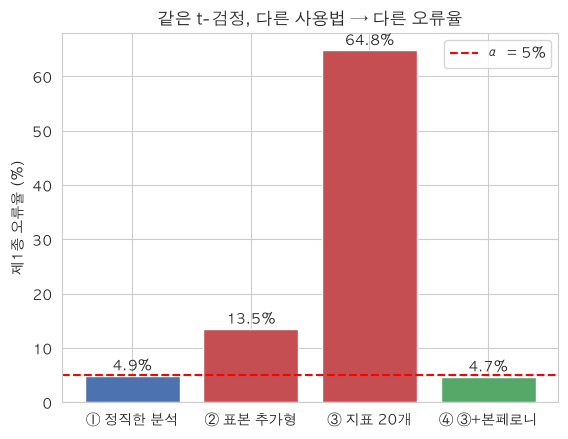

In [41]:
# 문제 3 · Q4 — 본페로니 보정 후 + 네 결과 비교
rng = np.random.default_rng(SEED)
bonf = np.mean([many_metrics(rng, cutoff=0.05 / 20) for _ in range(N_SIM)]) * 100   # 기준을 0.05/20으로

labels = ["① 정직한 분석", "② 표본 추가형", "③ 지표 20개", "④ ③+본페로니"]
values = [honest, peek, multi, bonf]
colors = ["#4C72B0", "#C44E52", "#C44E52", "#55A868"]

plt.bar(labels, values, color=colors)
plt.axhline(5, color="red", linestyle="--", label="α = 5%")
for i, v in enumerate(values):
    plt.text(i, v + 1, f"{v:.1f}%", ha="center")
plt.ylabel("제1종 오류율 (%)")
plt.title("같은 t-검정, 다른 사용법 → 다른 오류율")
plt.legend(); plt.show()

### 📝 해석

**결론: 같은 t-검정 함수인데, 정직하게 쓰면 오류율 4.9%, 표본을 몰래 늘리면 13.5%, 지표 20개 중 골라 보고하면 64.8%였다. 본페로니 보정을 하면 다시 5% 아래로 내려온다.**

| 방식 | 제1종 오류율 | 기준 5% 대비 |
|---|---|---|
| ① 정직한 분석 | 4.9% | ✅ 지켜짐 |
| ② 표본 추가형 | 13.5% | ❌ 약 2.7배 |
| ③ 지표 20개 골라 보고 | 64.8% (이론 64.2%) | ❌ 약 13배 |
| ④ ③ + 본페로니 | 5% 이하 | ✅ 회복 |

- **문제는 도구가 아니라 쓰는 방식입니다.** 네 경우 모두 `stats.ttest_ind`를 똑같이 썼습니다.

### 🧠 데이터를 어떻게 읽을까요?

**Q1. Q1의 값이 5%에 가까웠다는 것은 무엇을 뜻하나요? 가설검정은 원래 무엇을 보장하나요?**
→ **가설검정은 "정해진 절차를 지켰을 때 제1종 오류가 α 이하"를 보장합니다.** Q1은 그 보장이 지켜지는 모습입니다.
- 이유: 차이가 0인 세계에서도 20번 중 1번은 우연히 p < 0.05가 나옵니다. 그 비율을 α로 묶어 두는 것이 검정의 약속이고, 그 약속은 '한 번만, 미리 정한 대로' 검정했을 때만 성립합니다.

**Q2. Q2와 Q3에서 오류율이 뛴 이유는? 두 해킹의 메커니즘은 같나요?**
→ **둘 다 "우연에게 기회를 여러 번 준" 것은 같지만, 방식이 다릅니다.**
- Q2(표본 추가형): **같은 질문을 여러 번** 물었습니다. 데이터가 쌓이면서 p-값이 오르내리는데, 0.05 아래로 내려간 순간 멈추니 우연한 저점을 잡게 됩니다. 앞의 데이터를 재사용하므로 검정끼리 독립이 아니라 오류가 64%까지는 안 뛰고 13.5%에 그쳤습니다.
- Q3(다중비교형): **서로 다른 20개 질문**을 던지고 하나만 골랐습니다. 독립 검정이라 1 − 0.95²⁰ 공식이 그대로 맞습니다.

**Q3. "지표 20개를 재고 유의한 하나만 보고한" 연구를 신뢰할 수 있나요?**
→ **그 결과만으로는 신뢰할 수 없습니다.** 효과가 전혀 없어도 64% 확률로 '유의한 지표 하나'가 나오기 때문입니다.
- 이유: 동전을 20번 던져 앞면이 한 번이라도 나오는 건 거의 확실합니다. 몇 개를 쟀는지 밝히지 않은 '유의한 하나'는 동전 앞면 한 번과 다를 게 없습니다.

**Q4. HARKing(결과를 본 뒤 가설을 만드는 행위)은 Q2·Q3 중 어느 쪽과 닮았나요?**
→ **Q3과 닮았습니다.**
- 이유: 여러 결과를 훑어본 뒤 유의하게 나온 것을 골라 "처음부터 이걸 확인하려 했다"고 가설을 만드는 것은, 20개 지표 중 하나를 골라 보고하는 것과 구조가 같습니다.

**Q5. 사전 등록(Preregistration)은 Q2와 Q3을 각각 어떻게 막아 주나요?**
→ **Q2에 대해서는 표본크기와 종료 조건을, Q3에 대해서는 주 지표를 미리 고정해 막습니다.**
- 이유: 사전 등록은 데이터를 보기 전에 "몇 명을 모으고, 어떤 지표 하나로, 어떤 검정을 할지"를 공개적으로 적어 두는 것입니다. 나중에 표본을 늘리거나 다른 지표로 갈아타면 바로 드러납니다.

**Q6. 문제 2의 '표본수 사전 설계'는 Q2를 막는 데 어떤 역할을 하나요?**
→ **"언제 멈출지"를 결과와 무관하게 미리 정해 줍니다.** 검정력 분석으로 n = 64라고 정했다면, 64명이 모일 때까지 기다렸다가 딱 한 번 검정하면 됩니다.
- 이유: 표본 추가형 해킹의 핵심은 '결과를 보고 멈추는 것'입니다. 멈추는 규칙을 미리 숫자로 박아 두면 그 여지가 사라집니다.

> 💡 **주의:** 지표 20개를 훑는 것 자체가 잘못은 아닙니다. 그것은 **탐색형 연구**입니다. 잘못은 그것을 **가설검증형인 척** 보고하는 데 있습니다. 탐색에서 찾은 것은 새 데이터로 다시 확인해야 검증이 됩니다.


---
# 2부 · 인과와 상관

<a id="p4"></a>
## 문제 4. 교란요인을 지우는 두 가지 방법 — 통제와 무작위화

### 📖 상황
7장에서 펭귄 부리는 전체로 보면 길수록 얇은데, 종별로 나누면 길수록 두꺼웠습니다. 원인은 **교란변수 '종'**이었습니다. 교란을 지우는 길은 두 가지입니다.
- ① **통제**: 층별로 나눠 보거나, 회귀식에 함께 넣기
- ② **무작위화**: 동전을 던져 배정하기 (RCT)

### 🧩 개념
- **교란변수(Confounder)**: X와 Y 양쪽에 영향을 주는 Z. 그림으로는 **X ← Z → Y**.
- **허위상관 / 심슨의 역설**: 교란 때문에 생긴 가짜 관계. 전체와 층별 결론의 방향이 뒤집힐 수도 있습니다.
- **선택 편향**: 처치를 받을지 스스로 고르면, 처치군과 대조군이 *처치 전부터* 다릅니다.
- **잠재결과**: 같은 사람의 "처치받았을 때 Y₁"과 "안 받았을 때 Y₀". 인과효과는 Y₁ − Y₀인데, 한 사람에게서 둘 다 볼 수는 없습니다. 그래서 *비교 가능한 두 집단*이 필요합니다.
- **통제는 이름을 아는 교란만, 무작위화는 이름을 모르는 교란까지** 지웁니다.

In [42]:
# 문제 4 · 데이터 준비 (1/2) — 펭귄 부리
bills = penguins.dropna(subset=["bill_length_mm", "bill_depth_mm", "species"])
print("분석에 사용할 데이터: %d 행\n" % len(bills))
print("종별 부리 평균 — '종'이 두 변수 모두에 영향을 주고 있다는 단서")
print(bills.groupby("species")[["bill_length_mm", "bill_depth_mm"]].mean().round(2))

분석에 사용할 데이터: 342 행

종별 부리 평균 — '종'이 두 변수 모두에 영향을 주고 있다는 단서
           bill_length_mm  bill_depth_mm
species                                 
Adelie              38.79          18.35
Chinstrap           48.83          18.42
Gentoo              47.50          14.98


### 💻 Q1 · 전체 데이터 단순회귀

In [43]:
# 문제 4 · Q1 — 전체 데이터 단순회귀: 부리 두께 ~ 부리 길이
m_all = smf.ols("bill_depth_mm ~ bill_length_mm", data=bills).fit()   # .fit() = 적합(계수 추정)
print(f"기울기 = {m_all.params['bill_length_mm']:.4f},  p = {m_all.pvalues['bill_length_mm']:.2e}")
print("→ 이것만 보면: '부리가 길수록 얇다'는 (틀린) 결론")

기울기 = -0.0850,  p = 1.12e-05
→ 이것만 보면: '부리가 길수록 얇다'는 (틀린) 결론


### 💻 Q2 · 종별로 층을 나눠 회귀 (층별 분석)

In [44]:
# 문제 4 · Q2 — 종별로 층을 나눠 같은 회귀
rows = []
for sp, g in bills.groupby("species"):
    m = smf.ols("bill_depth_mm ~ bill_length_mm", data=g).fit()
    rows.append({"종": sp, "n": len(g),
                 "기울기": round(m.params["bill_length_mm"], 4),
                 "p-값": f"{m.pvalues['bill_length_mm']:.1e}"})
pd.DataFrame(rows)

,종,n,기울기,p-값
0,Adelie,151,0.1788,6.7e-07
1,Chinstrap,68,0.2222,1.5e-09
2,Gentoo,123,0.2048,1.0e-15


### 💻 Q3 · 종을 회귀식에 넣어 통제 (다중회귀)

In [45]:
# 문제 4 · Q3 — 종을 회귀식에 넣어 통제
m_ctrl = smf.ols("bill_depth_mm ~ bill_length_mm + C(species)", data=bills).fit()   # C(): 범주형 → 더미
pd.DataFrame({
    "Q1 전체(통제 없음)": [m_all.params["bill_length_mm"], m_all.pvalues["bill_length_mm"], m_all.rsquared],
    "Q3 종 통제":        [m_ctrl.params["bill_length_mm"], m_ctrl.pvalues["bill_length_mm"], m_ctrl.rsquared],
}, index=["기울기", "p-값", "R²"]).style.format("{:.4g}")

AttributeError: The '.style' accessor requires jinja2

### 💻 Q4 · 관찰연구: 수강생과 비수강생은 애초에 다르다

In [ ]:
# 문제 4 · 데이터 준비 (2/2) — 같은 학생 2,000명, 배정 방식만 다른 두 데이터
TRUE_EFFECT = 5.0                      # 강의의 진짜 효과: 기말 +5점
rng = np.random.default_rng(279)
n = 2000

pre_score   = rng.normal(60, 10, n)    # 교란요인 ① 사전 성적
study_hours = rng.normal(10,  3, n)    # 교란요인 ② 주당 학습시간

# 잠재결과: 교란요인이 결과에도 직접 영향
Y0 = 20 + 0.7 * pre_score + 0.8 * study_hours + rng.normal(0, 5, n)   # 안 들었을 때
Y1 = Y0 + TRUE_EFFECT                                                    # 들었을 때

# (A) 관찰연구 — 성적 좋고 열심인 학생이 스스로 신청 (선택 편향)
signup_logit = -0.6 + 0.10 * (pre_score - 60) + 0.20 * (study_hours - 10)
course_obs = rng.binomial(1, 1 / (1 + np.exp(-signup_logit)))

# (B) RCT — 동전 던지기 배정
course_rct = rng.binomial(1, 0.5, n)

df_obs = pd.DataFrame({"pre_score": pre_score, "study_hours": study_hours,
                       "course": course_obs, "final_score": np.where(course_obs == 1, Y1, Y0)})
df_rct = pd.DataFrame({"pre_score": pre_score, "study_hours": study_hours,
                       "course": course_rct, "final_score": np.where(course_rct == 1, Y1, Y0)})

print("참 효과: %.1f점" % TRUE_EFFECT)
print("관찰연구 수강생 %d명 (%.1f%%) / RCT 수강생 %d명 (%.1f%%)" % (
    df_obs["course"].sum(), df_obs["course"].mean() * 100, df_rct["course"].sum(), df_rct["course"].mean() * 100))

참 효과: 5.0점
관찰연구 수강생 751명 (37.5%) / RCT 수강생 1012명 (50.6%)


In [ ]:
# 문제 4 · Q4 — 관찰연구: 단순 평균 차이와 교란요인 비교
cols = ["pre_score", "study_hours", "final_score"]
obs_means = df_obs.groupby("course")[cols].mean()
print(obs_means.round(2))

naive_obs = obs_means.loc[1, "final_score"] - obs_means.loc[0, "final_score"]
print(f"\n단순 평균 차이: {naive_obs:+.2f}점   (참 효과 {TRUE_EFFECT:+.1f}점, 과대추정 {naive_obs - TRUE_EFFECT:+.2f}점)")

        pre_score  study_hours  final_score
course                                     
0           57.05         9.71        67.87
1           64.74        11.10        79.21

단순 평균 차이: +11.34점   (참 효과 +5.0점, 과대추정 +6.34점)


### 💻 Q5 · RCT: 같은 학생들을 동전으로 배정하면

In [ ]:
# 문제 4 · Q5 — RCT: 같은 계산 + 두 방식의 교란요인 균형표
rct_means = df_rct.groupby("course")[cols].mean()
naive_rct = rct_means.loc[1, "final_score"] - rct_means.loc[0, "final_score"]
print(f"RCT 단순 평균 차이: {naive_rct:+.2f}점   (참 효과 {TRUE_EFFECT:+.1f}점)\n")

balance = pd.DataFrame({
    "관찰연구 차이(수강−비수강)": obs_means.loc[1, ["pre_score", "study_hours"]] - obs_means.loc[0, ["pre_score", "study_hours"]],
    "RCT 차이(수강−비수강)":     rct_means.loc[1, ["pre_score", "study_hours"]] - rct_means.loc[0, ["pre_score", "study_hours"]],
})
balance.round(2)

RCT 단순 평균 차이: +4.98점   (참 효과 +5.0점)



,관찰연구 차이(수강−비수강),RCT 차이(수강−비수강)
pre_score,7.69,0.07
study_hours,1.38,-0.01


### 📝 해설

**결론: 펭귄 부리의 음의 관계(−0.085)는 '종' 때문에 생긴 허위상관이었다. 종을 통제하면 기울기는 +0.20으로 뒤집힌다. 학생 데이터에서는 관찰연구의 단순 비교가 참 효과의 두 배 넘게(+11.3점) 부풀었지만, RCT는 아무것도 통제하지 않고도 +4.98점으로 참값 5점을 맞혔다.**

**펭귄 부리**
| 분석 | 기울기 | p-값 | R² |
|---|---|---|---|
| Q1 전체 (통제 없음) | −0.085 | 1.1×10⁻⁵ | 0.055 |
| Q2 Adelie / Chinstrap / Gentoo | +0.18 / +0.22 / +0.20 | 모두 매우 작음 | — |
| Q3 종 통제 다중회귀 | **+0.200** | 8.7×10⁻²⁶ | **0.769** |

**학생 강의 (참 효과 +5.0점)**
| | 단순 평균 차이 | 사전성적 차이 | 학습시간 차이 |
|---|---|---|---|
| 관찰연구 | **+11.34점** | +7.69 | +1.38 |
| RCT | **+4.98점** | +0.07 | −0.01 |

### 🧠 데이터를 어떻게 읽을까요?

**Q1. Q1의 기울기는 음수인데 Q2·Q3는 양수였습니다. 부호가 뒤집힌 이유와 그 이름은?**
→ **'종'이라는 교란변수 때문이고, 이 현상을 심슨의 역설(허위상관)이라 부릅니다.**
- 이유: Adelie는 부리가 짧고(38.8mm) 두껍고(18.4mm), Gentoo는 길고(47.5mm) 얇습니다(15.0mm). 종을 섞으면 "종이 바뀔 때 길이는 늘고 두께는 주는" 흐름이 생겨, 종 안에서의 양의 관계를 덮어 버립니다.

**Q2. 층별 분석(Q2)과 다중회귀(Q3)는 같은 결론을 줬습니다. 차이는? 층이 아주 많아지면 어느 쪽이 유리할까요?**
→ **층별 분석은 층마다 따로 기울기를 주고, 다중회귀는 "층마다 기울기가 같다"고 가정하고 하나의 기울기를 줍니다.** 층이 많으면 다중회귀가 유리합니다.
- 이유: 층이 많아지면 층마다 표본이 작아져 기울기가 불안정해집니다. 다중회귀는 모든 데이터를 한 번에 쓰므로 안정적이지만, 대신 '기울기 동일' 가정을 덧붙입니다. Q2에서 세 종의 기울기가 0.18~0.22로 비슷했으니 이 가정은 무리가 없어 보입니다.

**Q3. 관찰연구의 단순 비교값(+11.34)이 참 효과(5점)와 크게 달랐던 이유는?**
→ **수강생이 처음부터 사전 성적이 7.7점 높고 학습시간도 1.4시간 많았기 때문입니다.**
- 이유: 성적 좋고 열심인 학생이 스스로 신청했습니다(선택 편향). 이 학생들은 강의를 안 들었어도 기말 점수가 높았을 사람들입니다. 단순 비교에는 강의 효과(5점)와 원래 실력 차이(약 6.3점)가 섞여 있습니다.

**Q4. RCT는 사전 성적도 학습시간도 통제하지 않았는데 어떻게 참값에 가까웠나요?**
→ **동전 던지기로 배정하니 두 집단의 사전 성적·학습시간이 거의 같아졌기 때문입니다(차이 0.07, −0.01).**
- 이유: 배정이 학생의 특성과 무관하니, 어떤 특성이든 두 집단에 고르게 나뉩니다. 두 집단이 '처치 빼고 같은' 상태가 되므로 단순 평균 차이가 곧 처치효과가 됩니다.

**Q5. 통제와 무작위화의 결정적 차이는? 모르는 교란이 있다면 어느 쪽이 안전한가요?**
→ **통제는 이름을 아는(측정한) 교란만 지우고, 무작위화는 모르는 교란까지 지웁니다. 그래서 무작위화가 안전합니다.**
- 이유: Q3에서 지운 건 '종' 하나뿐이고, 성별·서식지·측정 연도는 그대로입니다. 그 목록이 완전하다고 아무도 보장해 주지 않습니다. RCT를 '인과추론의 황금 표준'이라 부르는 이유입니다.

**Q6. 현실에서 RCT가 늘 가능한가요? 불가능한 예는?**
→ **아닙니다.** 예를 들면,
- **윤리적으로 불가능**: 흡연이 건강에 해로운지 알기 위해 사람들을 무작위로 담배 피우게 할 수 없습니다.
- **현실적으로 불가능**: 한 도시에만 정책을 시행하는 것, 금리 인상, 학교 무상급식처럼 개인 단위로 동전을 던질 수 없는 경우입니다.
- 그래서 다음 문제의 **준실험 방법(PSM, DiD)**이 필요합니다.


---
<a id="p5"></a>
## 문제 5. 미니 프로젝트 — 실험할 수 없을 때

### 📖 상황
무작위 배정이 불가능하면 관찰 데이터만으로 인과효과에 다가가야 합니다. 두 방법을 씁니다.
- ① **경향점수 짝짓기(PSM)**: 처치받을 '경향'이 비슷한 사람끼리 짝지어 '통계적 쌍둥이' 집단을 만듭니다.
- ② **이중차분법(DiD)**: 통제군의 변화를 '정책이 없었다면 일어났을 변화'로 삼아 실험군의 변화에서 뺍니다.

> 🎯 진짜 목표는 추정값이 아니라 **가정을 검증하는 절차**까지 해 보는 것입니다.

### 🧩 개념
**PSM**
- **경향점수** = 관측된 특성(pre_score, study_hours)으로 예측한 '처치받을 확률'. 로지스틱 회귀로 구합니다.
- 경향점수가 같은 두 사람은 관측된 교란요인 측면에서 비슷합니다 → 그런 쌍끼리 비교하면 RCT를 흉내 낼 수 있습니다.
- **ATT**: 실제로 처치를 받은 사람들에게서의 평균 효과.
- **공변량 균형 점검**: 짝짓기 후 교란요인 평균이 비슷해졌는지 *반드시* 확인합니다.
- **겹침(common support)**: 처치군과 대조군의 경향점수 분포가 겹쳐야 짝을 찾을 수 있습니다.

**DiD**
- 인과효과 = ΔA − ΔB = **(A₂ − A₁) − (B₂ − B₁)**  (A = 실험군, B = 통제군, 1 = 이전, 2 = 이후)
- **평행추세 가정**: 정책이 없었다면 두 집단은 같은 속도로 변했을 것이다. 정책 이전 여러 시점을 그려 확인합니다.
- 회귀로는 `y ~ 실험군 * 이후` — 상호작용항 계수가 DiD 추정치입니다.
- **플라시보 검정**: 정책이 없던 구간에 같은 분석을 해서 0이 나오는지 봅니다.

In [ ]:
# 문제 5 · 데이터 준비 (1/2) — 문제 4의 관찰연구 데이터를 이어서 사용
print("관찰연구 df_obs: %d행 / 수강생 %d명 / 비수강생 %d명" % (
    len(df_obs), (df_obs["course"] == 1).sum(), (df_obs["course"] == 0).sum()))
print("단순 평균 비교(문제 4 Q4): %+.2f점 / 되찾아야 할 참 효과: %+.1f점" % (naive_obs, TRUE_EFFECT))

관찰연구 df_obs: 2000행 / 수강생 751명 / 비수강생 1249명
단순 평균 비교(문제 4 Q4): +11.34점 / 되찾아야 할 참 효과: +5.0점


### 💻 Q1 · 경향점수 추정

In [ ]:
# 문제 5 · Q1 — 경향점수 추정 (로지스틱 회귀)
X = sm.add_constant(df_obs[["pre_score", "study_hours"]])      # 설명변수 + 절편
logit = sm.Logit(df_obs["course"], X).fit(disp=0)             # 반응변수: 수강 여부(0/1)
df_obs["ps"] = logit.predict(X)                               # 경향점수 = 수강할 확률

plt.hist(df_obs.loc[df_obs["course"] == 1, "ps"], bins=30, alpha=0.5, label="수강생", density=True)
plt.hist(df_obs.loc[df_obs["course"] == 0, "ps"], bins=30, alpha=0.5, label="비수강생", density=True)
plt.title("경향점수 분포 — 겹치는 구간이 있어야 짝을 찾을 수 있다")
plt.xlabel("경향점수 (수강할 확률)"); plt.ylabel("밀도")
plt.legend(); plt.show()
print(logit.params.round(3))

NameError: name 'df_obs' is not defined

### 💻 Q2 · 1:1 짝짓기로 ATT 추정

In [ ]:
# 문제 5 · Q2 — 1:1 최근접 짝짓기로 ATT 추정
treated = df_obs[df_obs["course"] == 1]
control = df_obs[df_obs["course"] == 0]

nn = NearestNeighbors(n_neighbors=1).fit(control[["ps"]])     # 대조군의 경향점수로 학습
dist, idx = nn.kneighbors(treated[["ps"]])                    # 수강생마다 가장 가까운 비수강생
matched_control = control.iloc[idx.flatten()]                 # (복원 짝짓기: 같은 대조군이 여러 번 뽑힐 수 있음)

att = treated["final_score"].mean() - matched_control["final_score"].mean()
print(f"① 단순 평균 비교 : {naive_obs:+.2f}점")
print(f"② PSM 이후 ATT   : {att:+.2f}점")
print(f"③ 참 효과        : {TRUE_EFFECT:+.2f}점")

① 단순 평균 비교 : +11.34점
② PSM 이후 ATT   : +5.02점
③ 참 효과        : +5.00점


### 💻 Q3 · 공변량 균형 점검

In [ ]:
# 문제 5 · Q3 — 공변량 균형 점검 (짝짓기 전 vs 후)
covs = ["pre_score", "study_hours"]
pd.DataFrame({
    "짝짓기 전 차이": treated[covs].mean() - control[covs].mean(),
    "짝짓기 후 차이": treated[covs].mean().values - matched_control[covs].mean().values,
}, index=covs).round(3)

,짝짓기 전 차이,짝짓기 후 차이
pre_score,7.687,0.074
study_hours,1.382,0.025


### 💻 Q4 · DiD — 평행추세 확인

In [ ]:
# 문제 5 · 데이터 준비 (2/2) — 서울(실험군)·부산(통제군) 패널, 2020~2025
POLICY_YEAR = 2024        # 서울 무료 공공 와이파이 도입
TRUE_DID    = 4.0         # 정책의 진짜 효과: +4 GB
rng = np.random.default_rng(2024)

records = []
for city, baseline, is_seoul in [("서울", 15.0, 1), ("부산", 10.0, 0)]:
    for person in range(300):
        person_effect = rng.normal(0, 2.0)                    # 사람마다 타고난 차이
        for year in range(2020, 2026):
            time_trend = 1.5 * (year - 2020)                  # 두 도시에 똑같은 시간 추세
            policy = TRUE_DID if (is_seoul and year >= POLICY_YEAR) else 0.0
            records.append((city, is_seoul, person + is_seoul * 300, year,
                            baseline + person_effect + time_trend + policy + rng.normal(0, 1.0)))

panel = pd.DataFrame(records, columns=["city", "is_seoul", "person_id", "year", "data_usage"])
print("패널 데이터: %d행 (도시 2 × 300명 × 6년)" % len(panel))
print(panel.groupby(["year", "city"])["data_usage"].mean().unstack().round(2))

패널 데이터: 3600행 (도시 2 × 300명 × 6년)
city     부산     서울
year              
2020  10.16  14.69
2021  11.54  16.27
2022  13.08  17.71
2023  14.60  19.22
2024  16.11  24.74
2025  17.59  26.36


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


... (39 outputs left out)

findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


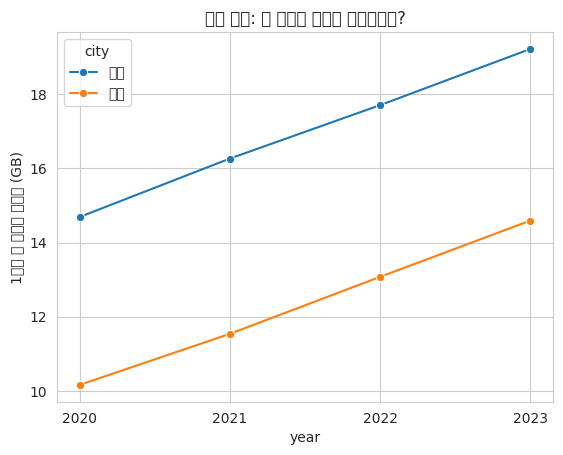

city,부산,서울,격차(서울−부산)
year,,,
2020,10.16,14.69,4.53
2021,11.54,16.27,4.73
2022,13.08,17.71,4.63
2023,14.60,19.22,4.63


In [ ]:
# 문제 5 · Q4 — 평행추세 확인 (정책 이전 2020~2023만)
pre = panel[panel["year"] < POLICY_YEAR]
sns.lineplot(data=pre, x="year", y="data_usage", hue="city", marker="o", errorbar=None)
plt.title("정책 이전: 두 도시가 나란히 움직이는가?")
plt.xticks(range(2020, 2024)); plt.ylabel("1인당 월 데이터 사용량 (GB)")
plt.show()

gap = pre.groupby(["year", "city"])["data_usage"].mean().unstack()
gap["격차(서울−부산)"] = gap["서울"] - gap["부산"]
gap.round(2)

### 💻 Q5 · 2×2 DiD 회귀

In [ ]:
# 문제 5 · Q5 — 2×2 DiD 회귀 (2023 vs 2024)
# 계수 세 개의 의미
# is_seoul         : 정책 전(2023) 서울과 부산의 원래 격차
# is_post          : 부산(통제군)의 2023→2024 변화 = 정책 없이도 일어났을 시간 변화
# is_seoul:is_post : 서울이 부산보다 '추가로' 더 변한 양 = 정책효과(DiD)
did_df = panel[panel["year"].isin([2023, 2024])].copy()
did_df["is_post"] = (did_df["year"] == 2024).astype(int)

m_did = smf.ols("data_usage ~ is_seoul * is_post", data=did_df).fit()   # *: 주효과 둘 + 상호작용
print(m_did.summary().tables[1])

# 손으로 검산: (A2 − A1) − (B2 − B1)
g = did_df.groupby(["is_seoul", "is_post"])["data_usage"].mean()
hand = (g[1, 1] - g[1, 0]) - (g[0, 1] - g[0, 0])
print(f"\n상호작용 계수 = {m_did.params['is_seoul:is_post']:.4f}  /  손 계산 = {hand:.4f}  /  참 효과 = {TRUE_DID}")

                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           14.5950      0.128    114.112      0.000      14.344      14.846
is_seoul             4.6277      0.181     25.584      0.000       4.273       4.983
is_post              1.5155      0.181      8.378      0.000       1.161       1.870
is_seoul:is_post     4.0064      0.256     15.662      0.000       3.505       4.508

상호작용 계수 = 4.0064  /  손 계산 = 4.0064  /  참 효과 = 4.0


### 💻 Q6 · 플라시보 검정

In [ ]:
# 문제 5 · Q6 — 플라시보 검정: 정책이 없던 2022 vs 2023
pl_df = panel[panel["year"].isin([2022, 2023])].copy()
pl_df["is_post"] = (pl_df["year"] == 2023).astype(int)
m_pl = smf.ols("data_usage ~ is_seoul * is_post", data=pl_df).fit()

coef, p = m_pl.params["is_seoul:is_post"], m_pl.pvalues["is_seoul:is_post"]
print(f"가짜 정책효과 = {coef:+.3f} GB,  p = {p:.3f}")
print("→ 통과: 정책이 없던 구간에서 효과가 0과 구별되지 않음" if p >= 0.05
      else "→ 실패: 정책이 없는데 효과가 나옴 → 평행추세 위반이나 다른 사건을 의심")

가짜 정책효과 = -0.003 GB,  p = 0.990
→ 통과: 정책이 없던 구간에서 효과가 0과 구별되지 않음


### 💻 Q7 · 보고 문장 (정답 예시)

In [ ]:
# 문제 5 · Q7 — 보고 문장 (정답 예시)
# PSM 보고 문장:
#   "사전 성적과 주당 학습시간으로 추정한 경향점수로 수강생 751명을 비수강생과 1:1 최근접 짝짓기한 결과,
#    강의의 평균 처치효과(ATT)는 +5.02점으로 추정되었다(단순 비교 +11.34점).
#    짝짓기 후 두 공변량의 평균 차이는 0.07점, 0.03시간으로 균형이 확인되었다.
#    다만 경향점수 모형에 넣지 않은 관측되지 않은 교란(예: 타고난 이해력)은 보정되지 않았다."
#
# DiD 보고 문장:
#   "서울(실험군)과 부산(통제군)의 2023→2024년 변화를 비교한 이중차분 회귀에서,
#    무료 공공 와이파이 정책효과는 +4.01 GB(95% CI 3.51~4.51, p<0.001)로 추정되었다.
#    정책 이전 2020~2023년 두 도시의 격차는 4.53~4.73 GB로 일정해 평행추세 가정을 지지했고,
#    정책이 없던 2022→2023년에 같은 분석을 적용한 플라시보 검정에서는 효과가 −0.003 GB(p=0.99)로 나타나지 않았다."

### 📝 해설

**결론: PSM은 단순 비교의 +11.34점을 +5.02점으로 바로잡았고, 짝짓기 후 교란요인 차이는 0에 가까워졌다. DiD는 정책효과를 +4.01 GB로 추정했으며, 평행추세 확인과 플라시보 검정을 모두 통과했다.**

**PSM 결과**
| | 단순 비교 | PSM ATT | 참 효과 |
|---|---|---|---|
| 강의 효과 | +11.34점 | **+5.02점** | +5.00점 |

| 공변량 | 짝짓기 전 차이 | 짝짓기 후 차이 |
|---|---|---|
| pre_score | 7.69 | 0.07 |
| study_hours | 1.38 | 0.03 |

**DiD 결과**
- 정책 이전 격차(서울 − 부산): 2020 4.53 / 2021 4.73 / 2022 4.63 / 2023 4.63 GB → 거의 일정
- 2×2 회귀 계수: is_seoul 4.63 (원래 격차) / is_post 1.52 (공통 시간 변화) / **is_seoul:is_post 4.01 (정책효과)**
- 손 계산 (A₂ − A₁) − (B₂ − B₁) = 4.0064 → 회귀 계수와 소수점까지 일치
- 플라시보(2022→2023): −0.003 GB, p = 0.99 → 통과

### 🧠 데이터를 어떻게 읽을까요?

**Q1. PSM이 한 일을 한 문장으로 설명하면?**
→ **"수강생마다 수강할 가능성이 비슷했던 비수강생을 찾아 짝지어, 관측된 교란요인이 같은 두 집단을 만들어 비교했다."**
- 이유: 단순 비교는 '원래 잘하던 학생 vs 덜 하던 학생'을 비교했지만, PSM은 '비슷하게 잘하던 학생 중 들은 사람 vs 안 들은 사람'을 비교합니다.

**Q2. 짝짓기 후 교란요인 차이는 어떻게 변했나요? 차이가 크게 남았다면 어떻게 해야 하나요?**
→ **7.69 → 0.07, 1.38 → 0.03으로 거의 0이 되었습니다.** 차이가 남았다면 경향점수 모형을 고치거나(변수 추가, 상호작용), 짝 사이 거리에 상한(캘리퍼)을 두거나, 짝 수를 바꾸어 다시 맞춥니다.
- 이유: 균형이 맞지 않은 상태의 ATT는 여전히 교란이 섞인 값입니다. 균형 점검은 '짝짓기가 됐다고 가정'하지 않고 '확인'하는 단계입니다.

**Q3. 관측하지 못한 교란(예: 타고난 이해력)이 있다면 ATT를 인과효과라 부를 수 있나요?**
→ **그대로 부를 수는 없습니다.** PSM은 모형에 넣은 변수만 균형을 맞춥니다.
- 이유: 문제 4의 RCT는 모르는 교란까지 고르게 흩뿌렸지만, PSM은 측정한 것만 맞춥니다. "관측된 교란 외에는 없다"는 가정 위에서만 인과효과로 읽을 수 있습니다. 이 데이터에서 맞은 것은 우리가 *교란이 두 개뿐인 세계를 직접 만들었기* 때문입니다.

**Q4. 정책 이전 4년간 격차가 거의 일정했다는 것은 어떤 가정을 지지하나요? 격차가 벌어지고 있었다면?**
→ **평행추세 가정을 지지합니다.** 만약 이전부터 격차가 벌어지고 있었다면, Q5의 계수에는 정책효과와 원래 벌어지던 추세가 섞여 있으므로 **정책효과를 과대(또는 과소) 추정**했다고 읽어야 합니다.
- 이유: DiD는 "정책이 없었다면 서울도 부산만큼만 변했을 것"이라는 가정으로 부산의 변화를 빼 줍니다. 그 가정이 틀리면 빼는 값이 틀립니다. 시점이 두 개뿐이면 이 확인 자체가 불가능하다는 점도 중요합니다.

**Q5. 상호작용항이 왜 정책효과인가요?**
→ **상호작용항은 "서울이면서 정책 이후"일 때만 더해지는 값, 즉 서울이 부산보다 추가로 더 변한 양이기 때문입니다.**
- 이유: 네 평균을 직접 계산하면 (24.74 − 19.22) − (16.11 − 14.60) ≈ 5.52 − 1.52 = 4.01입니다. 회귀는 이 뺄셈을 대신 해 주고, 덤으로 표준오차와 신뢰구간을 붙여 줍니다.

**Q6. 플라시보 검정이 유의하게 나왔다면 무엇을 의심해야 하나요?**
→ **평행추세 가정이 깨졌거나, 같은 시기에 서울에만 일어난 다른 사건이 있었다고 의심해야 합니다.**
- 이유: 정책이 없던 구간에서 효과가 나왔다면, 그 '효과'는 정책이 아닌 다른 무언가가 만든 것입니다. 그러면 실제 정책 구간의 추정치에도 같은 것이 섞여 있을 수 있습니다. 반대로 통과했다고 방법이 옳음이 *증명*된 것은 아닙니다. 반증에 실패했을 뿐입니다.

**Q7. PSM과 DiD는 각각 언제 쓰나요? 데이터 요구조건은?**
→ **PSM은 한 시점의 단면 데이터에서 처치군과 대조군의 관측 특성이 다를 때, DiD는 처치 전후 여러 시점의 패널 데이터가 있고 처치 시점이 명확할 때** 씁니다.
- 이유: DiD는 시간축이 없으면 쓸 수 없습니다. 반대로 처치 시점이 분명한 정책이라면 DiD가 더 강력한데, 시간에 따라 변하지 않는 관측되지 않은 차이(도시의 원래 성향 등)를 자동으로 빼 주기 때문입니다.

> 💡 **이 실습 전체의 결론:** PSM·DiD는 RCT의 대체품이 아닙니다. 무작위화가 자동으로 해 주던 일을 **가정을 명시적으로 걸고** 대신 하는 차선책입니다. 그래서 "어떤 가정을 걸었고 어떻게 검증했는지" 말할 수 없다면 그 추정치는 쓸 수 없습니다.
>
> 📌 다루지 못한 준실험 방법으로 **회귀 불연속 설계(RDD)**가 있습니다. "커트라인 바로 위·아래는 거의 같은 사람들"이라는 발상으로, 장학금 커트라인처럼 기준점이 있는 정책에서 강력합니다.


---
<a id="summary"></a>
## 🧠 마지막: 한눈에 보는 정리

### 9장 · 가설검정의 주의점
| 질문 | 답 | 근거 (이 노트) |
|---|---|---|
| p-값이 작으면 차이가 큰가? | 아니다. n이 크면 작은 차이도 유의 | 문제 1: 32g, n=20,000이면 100% 유의, d는 0.07 그대로 |
| 무엇을 함께 보고해야 하나? | 효과크기, 신뢰구간, 표본크기 | 문제 1 Q5 |
| 몇 명을 모아야 하나? | α·검정력·효과크기를 정하고 n을 계산 | 문제 2: d=0.5면 64명, d=0.074면 2,852명 |
| "유의하지 않음"은 "차이 없음"인가? | 아니다. 검정력이 낮으면 정보 부족 | 문제 2 Q2 |
| p-값의 보장은 언제 유효한가? | 미리 정한 절차대로 한 번 검정할 때만 | 문제 3: 4.9% → 13.5% → 64.8% |
| 여러 번 검정하면? | 보정(본페로니 등)과 사전 등록 | 문제 3 Q4 |

### 10장 · 인과와 상관
| 질문 | 답 | 근거 (이 노트) |
|---|---|---|
| 상관이 인과가 아닌 이유는? | 교란변수가 가짜 관계를 만든다 | 문제 4: 부리 기울기 −0.085 → +0.20 |
| 교란을 지우는 방법은? | 통제(층별·회귀) / 무작위화(RCT) | 문제 4 Q2·Q3·Q5 |
| 왜 RCT가 황금 표준인가? | 모르는 교란까지 고르게 섞는다 | 문제 4: 관찰 +11.34 vs RCT +4.98 |
| 실험이 불가능하면? | PSM(단면) · DiD(패널) — 가정을 명시하고 검증 | 문제 5: ATT +5.02, DiD +4.01 |
| 가정은 어떻게 검증하나? | 공변량 균형, 평행추세 그래프, 플라시보 검정 | 문제 5 Q3·Q4·Q6 |

### 🔑 발표용 한 줄 요약
> **"p-값은 '있다/없다'만 말하고 크기는 효과크기가 말한다. p-값의 약속은 절차를 지킬 때만 유효하다. 그리고 관계를 원인으로 말하려면 교란을 지워야 하는데, 가장 확실한 건 무작위화이고, 안 될 땐 가정을 걸고 검증까지 보여 줘야 한다."**

### ⚠️ 끝까지 기억할 주의 5가지
1. **유의 ≠ 중요.** p-값 옆에 늘 효과크기와 신뢰구간을 적는다.
2. **표본크기는 데이터를 보기 전에** 검정력 분석으로 정한다.
3. **여러 번 보고, 여러 개 보고, 골라서 보고하면** 오류율은 5%가 아니다.
4. **통제는 아는 교란만, 무작위화는 모르는 교란까지** 지운다.
5. **준실험 결과는 가정과 검증 절차를 함께** 보고해야 쓸 수 있다.